In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    cutDataframe = dataframe.query(cut)
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']

In [4]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc_notrueptcons.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and w<1')

In [4]:
df_allreco = applyCut(pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all050124_rc_notrueptcons.csv', low_memory=False),\
                      'pts>15 and bs!=-9 and w<1')

In [5]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

In [6]:
df_allreco.to_csv('/vast/palmer/home.grace/ys668/output/run12/all050124_rc_notrueptcons.csv', index=False)

# Process PYTHIA6+GEANT

In [6]:
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [7]:
print(df_match.shape[0], df_allfake.shape[0])

2630097 1465062


In [8]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)],\
                       df_allreco[(df_allreco.pts>40) & (df_allreco.pts<60)]]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)]]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]]

In [9]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [10]:
plt.rcParams['font.size'] = 12

Text(30, -0.33, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

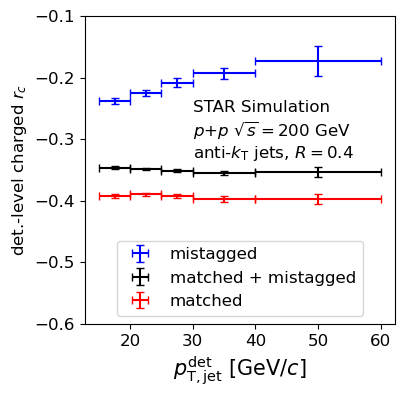

In [13]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('$p_{\mathrm{T,jet}}^{\mathrm{det}}}$ [GeV$/c$]', fontsize=15)
plt.ylabel('det.-level charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(30, -0.33, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

In [14]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [15]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [16]:
b_fake_array

[array([0.61905173, 0.38094827]),
 array([0.61242287, 0.38757713]),
 array([0.60405565, 0.39594435]),
 array([0.59652977, 0.40347023]),
 array([0.58635088, 0.41364912])]

In [17]:
b_match_array = []
b_match_err_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    p = y_reco[0]/sum(y_reco)
    q = y_reco[1]/sum(y_reco)
    print(np.array([p,q]))
    eff_count,eff_count_err,x = calc_hist(df_match_pts[ob+'s'], bins=[range_low, range_high], weights=df_match_pts['ws'], density=True)
    #print("count, err", eff_count,eff_count_err)
    sqrt_n_over_n = eff_count_err[0]/eff_count[0]
    #print((1/sqrt_n_over_n)**2)
    b_match_err_array.append(np.array([np.sqrt(p*q)*sqrt_n_over_n, np.sqrt(p*q)*sqrt_n_over_n]))
    print(np.array([np.sqrt(p*q)*sqrt_n_over_n, np.sqrt(p*q)*sqrt_n_over_n]))

[0.69613892 0.30386108]
[0.0014672 0.0014672]
[0.69480392 0.30519608]
[0.00127937 0.00127937]
[0.69601395 0.30398605]
[0.00168049 0.00168049]
[0.69861309 0.30138691]
[0.00208684 0.00208684]
[0.69865203 0.30134797]
[0.00423212 0.00423212]


In [18]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_291269/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [19]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.29936725, 0.24871326, 0.22291703, 0.2064793 , 0.19306711])

# Process data

In [20]:
observables1 = ['pt','b']
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9 and bs!=0')

In [21]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [22]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [23]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [24]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts['bs'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

In [25]:
print(b_data_array)

[array([337314., 178144.]), array([72379., 38554.]), array([16450.,  8688.]), array([4758., 2573.]), array([334., 153.])]


# 1. Mistagged subtraction

In [26]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [27]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print("pT bin", i)
    print("b_array raw data", b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, _ = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    print("b_array fake subtracted", b_fakesubtracted)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )
    b_fakesubtractederr = np.array([np.sqrt(p*(1-p)/n), np.sqrt(p*(1-p)/n)])*sum(b_fakesubtracted) # first find sigma(p), then scale up
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print("b_array unc.", b_fakesubtractederr)
    print("b_array frac. unc.", b_fakesubtractederr/b_fakesubtracted)

pT bin 0
b_array raw data [337314. 178144.]
b_array fake subtracted [241787.35901387 119359.39929276]
b_array unc. [282.68531454 282.68531454]
b_array frac. unc. [0.00116915 0.00236835]
pT bin 1
b_array raw data [72379. 38554.]
b_array fake subtracted [55481.9418755  27860.55029638]
b_array unc. [136.18755726 136.18755726]
b_array frac. unc. [0.00245463 0.00488819]
pT bin 2
b_array raw data [16450.  8688.]
b_array fake subtracted [13065.06044942  6469.25125312]
b_array unc. [65.77845436 65.77845436]
b_array frac. unc. [0.00503468 0.01016786]
pT bin 3
b_array raw data [4758. 2573.]
b_array fake subtracted [3855.03301837 1962.26719705]
b_array unc. [36.06055316 36.06055316]
b_array frac. unc. [0.00935415 0.01837698]
pT bin 4
b_array raw data [334. 153.]
b_array fake subtracted [278.86912984 114.10718633]
b_array unc. [8.99857064 8.99857064]
b_array frac. unc. [0.03226808 0.07886068]


Text(20, -0.25, 'STAR\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

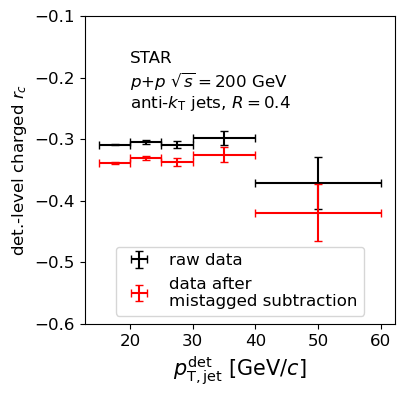

In [28]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='k', ls='none', label='raw data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='data after\nmistagged subtraction')
plt.xlabel('$p_{\mathrm{T,jet}}^{\mathrm{det}}}$ [GeV$/c$]', fontsize=15)
plt.ylabel('det.-level charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# 2. $p_T$ correction

In [29]:
reweight_array = []
reweight_err_array = []
for i in range(0,5):
    numerator = b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i])
    denominator = b_match_array[i]/sum(b_match_array[i])
    numerator_err = b_fakesubtractederr_array[i]/sum(b_fakesubtracted_array[i])
    print(numerator_err/numerator)
    denominator_err = b_match_err_array[i]/sum(b_match_array[i])
    print(denominator_err/denominator)
    reweight = numerator/denominator
    reweight_err = reweight*np.sqrt((numerator_err/numerator)**2+(denominator_err/denominator)**2)
    reweight_array.append(reweight)
    reweight_err_array.append(reweight_err)

[0.00116915 0.00236835]
[0.00210763 0.00482853]
[0.00245463 0.00488819]
[0.00184134 0.00419197]
[0.00503468 0.01016786]
[0.00241444 0.00552817]
[0.00935415 0.01837698]
[0.00298712 0.00692412]
[0.03226808 0.07886068]
[0.00605756 0.01404398]


In [30]:
reweight_array

[array([0.96173176, 1.08767168]),
 array([0.95812662, 1.09532818]),
 array([0.960938  , 1.08943732]),
 array([0.94857114, 1.11921181]),
 array([1.01571797, 0.96355909])]

In [31]:
reweight_err_array

[array([0.00231795, 0.00584959]),
 array([0.00294002, 0.00705335]),
 array([0.00536558, 0.01260861]),
 array([0.00931451, 0.02197925]),
 array([0.03334778, 0.07718247])]

([], [])

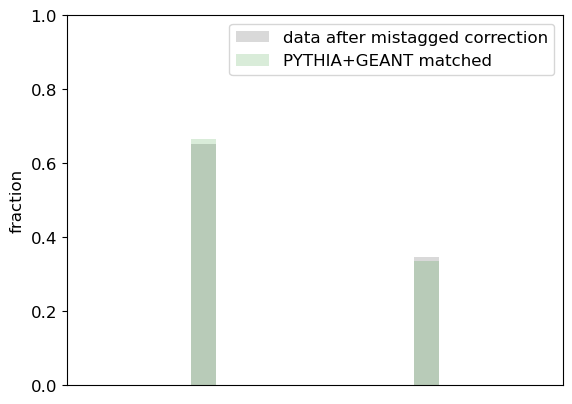

In [32]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=b_data_array[1]/sum(b_data_array[1]), color='k', alpha=0.15, label='data after mistagged correction')
plt.hist(x, weights=b_fakesubtracted_array[1]/sum(b_fakesubtracted_array[1]), ls='none', color='g', alpha=0.15, label='PYTHIA+GEANT matched')
#plt.errorbar(x+np.array([0.05,-0.05]), b_data_array[1][0]/sum(b_data_array[1]), yerr=y1err_array[0]/sum(b_data_array[1]), capsize=3, color='k', ls='none')
#plt.errorbar(x+np.array([0.05,-0.05]), b_fakesubtracted_array[1][0]/sum(b_fakesubtracted_array[1]), yerr=y1err_pythia_array[0]/sum(b_fakesubtracted_array[1]), capsize=3, color='g', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

Reweight PYTHIA6+GEANT

In [33]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pts'] > 40 and df_match.iloc[i]['pts'] < 60):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

anomaly reco pT: 64.71016459194377
anomaly reco pT: 60.15327606289669
anomaly reco pT: 62.85370544327776
anomaly reco pT: 62.96298659444578
anomaly reco pT: 60.49772873075676
anomaly reco pT: 60.46706627268168
anomaly reco pT: 64.14492779876475
anomaly reco pT: 60.89421353610575
anomaly reco pT: 65.35667922469173
anomaly reco pT: 62.63427678982773
anomaly reco pT: 60.21434194892271
anomaly reco pT: 62.15032283200955
anomaly reco pT: 60.27780299483247
anomaly reco pT: 61.03197986884235
anomaly reco pT: 60.25483540234041
anomaly reco pT: 63.99508646678217
anomaly reco pT: 61.56890722000404
anomaly reco pT: 60.8697641572812
anomaly reco pT: 64.23631221912824
anomaly reco pT: 63.19369788337173
anomaly reco pT: 60.96653998630141
anomaly reco pT: 62.74602930593176
anomaly reco pT: 65.45530859825888
anomaly reco pT: 60.03476303183356
anomaly reco pT: 63.08582949712376
anomaly reco pT: 66.83963074901102
anomaly reco pT: 61.03609940388197
anomaly reco pT: 70.61911542903617
anomaly reco pT: 66.7

anomaly reco pT: 61.066251011791365
anomaly reco pT: 60.35680014528115
anomaly reco pT: 71.33346402750679
anomaly reco pT: 62.32533358538276
anomaly reco pT: 60.92459101037781
anomaly reco pT: 61.37885697371845
anomaly reco pT: 61.45938905164215
anomaly reco pT: 60.16641125403288
anomaly reco pT: 60.09958144920835
anomaly reco pT: 60.511466054485055
anomaly reco pT: 62.350066426895815
anomaly reco pT: 66.11940247976565
anomaly reco pT: 62.15143279465398
anomaly reco pT: 60.697240773348895
anomaly reco pT: 61.79922547972766
anomaly reco pT: 62.11664288908429
anomaly reco pT: 66.38356449440559
anomaly reco pT: 70.6974465514885
anomaly reco pT: 62.49202362716819
anomaly reco pT: 61.065188221162096
anomaly reco pT: 61.23578848561933
anomaly reco pT: 61.52889434809697
anomaly reco pT: 60.31175466428895
anomaly reco pT: 63.22603510311757
anomaly reco pT: 60.18760080128897
anomaly reco pT: 62.83126138185055
anomaly reco pT: 61.152388176492224
anomaly reco pT: 63.75458910527901
anomaly reco pT

anomaly reco pT: 66.93636831586649
anomaly reco pT: 76.15786384596164
anomaly reco pT: 61.75583943405304
anomaly reco pT: 63.91093010671258
anomaly reco pT: 61.50802846399111
anomaly reco pT: 60.10045488287104
anomaly reco pT: 62.12533305728589
anomaly reco pT: 63.18755753863549
anomaly reco pT: 60.55812705404159
anomaly reco pT: 61.28085631237634
anomaly reco pT: 61.47743287524335
anomaly reco pT: 60.488095763928925
anomaly reco pT: 68.54885901919411
anomaly reco pT: 61.50396984848846
anomaly reco pT: 64.2182142798535
anomaly reco pT: 69.73367420432969
anomaly reco pT: 61.027595087508125
anomaly reco pT: 69.64749622782676
anomaly reco pT: 60.80583130708745
anomaly reco pT: 63.75691841415262
anomaly reco pT: 62.728856238000006
anomaly reco pT: 61.4228375011994
anomaly reco pT: 68.25512770432252
anomaly reco pT: 63.19510727748455
anomaly reco pT: 69.17229053514693
anomaly reco pT: 63.03810647468715
anomaly reco pT: 65.11635047674382
anomaly reco pT: 62.7859012143824
anomaly reco pT: 62.

anomaly reco pT: 65.25033525577705
anomaly reco pT: 61.76350377269977
anomaly reco pT: 67.91261516206957
anomaly reco pT: 64.18896871067179
anomaly reco pT: 61.55566986656164
anomaly reco pT: 61.01320265855932
anomaly reco pT: 66.46683297420948
anomaly reco pT: 60.719874837864914
anomaly reco pT: 63.323007001359706
anomaly reco pT: 61.75751789795584
anomaly reco pT: 65.47874514245692
anomaly reco pT: 63.8332260563184
anomaly reco pT: 65.86571741812644
anomaly reco pT: 61.25108554868977
anomaly reco pT: 61.947579640882736
anomaly reco pT: 63.82176843555475
anomaly reco pT: 63.46254812809013
anomaly reco pT: 62.96891790372958
anomaly reco pT: 64.35138414682795
anomaly reco pT: 64.48172194800236
anomaly reco pT: 61.26632928367613
anomaly reco pT: 63.2261305431496
anomaly reco pT: 61.77634558122546
anomaly reco pT: 60.86607307973257
anomaly reco pT: 60.21395499719272
anomaly reco pT: 60.09408616047344
anomaly reco pT: 60.99685047564388
anomaly reco pT: 60.16363338769977
anomaly reco pT: 63

anomaly reco pT: 61.2409003635572
anomaly reco pT: 60.39707499656056
anomaly reco pT: 61.99196169405341
anomaly reco pT: 60.62075385730599
anomaly reco pT: 61.14995283043609
anomaly reco pT: 66.04902795304733
anomaly reco pT: 60.9882253190428
anomaly reco pT: 66.7477555786966
anomaly reco pT: 61.708920284156285
anomaly reco pT: 64.36438487503408
anomaly reco pT: 62.94062266284301
anomaly reco pT: 63.95810430897519
anomaly reco pT: 62.44423781464371
anomaly reco pT: 75.46724224373281
anomaly reco pT: 61.80903146481187
anomaly reco pT: 62.13383225030382
anomaly reco pT: 66.75514905802402
anomaly reco pT: 66.14452877031708
anomaly reco pT: 63.09405627123977
anomaly reco pT: 64.90408598375983
anomaly reco pT: 63.48728395117119
anomaly reco pT: 61.28346182911763
anomaly reco pT: 66.20971847276358
anomaly reco pT: 60.79420789744857
anomaly reco pT: 61.510335938526346
anomaly reco pT: 63.60463563764089
anomaly reco pT: 62.73743231404073
anomaly reco pT: 65.7725494015351
anomaly reco pT: 63.11

anomaly reco pT: 62.86096768496176
anomaly reco pT: 62.16056113957712
anomaly reco pT: 61.96069542684406
anomaly reco pT: 61.08044654494434
anomaly reco pT: 61.09486273833345
anomaly reco pT: 61.61981682325583
anomaly reco pT: 60.1205165345292
anomaly reco pT: 65.54303934620583
anomaly reco pT: 61.85195587271151
anomaly reco pT: 60.484709187535344
anomaly reco pT: 62.79148753043836
anomaly reco pT: 65.45394705223177
anomaly reco pT: 60.47310394891137
anomaly reco pT: 60.69591432542661
anomaly reco pT: 73.17949617801028
anomaly reco pT: 61.87642099724723
anomaly reco pT: 62.033255571884375
anomaly reco pT: 64.2315669762808
anomaly reco pT: 65.90115509233549
anomaly reco pT: 62.01507656506754
anomaly reco pT: 64.34097510153335
anomaly reco pT: 66.61530082068789
anomaly reco pT: 63.67323508181137
anomaly reco pT: 62.32187202592208
anomaly reco pT: 67.88504705434883
anomaly reco pT: 71.60937468564357
anomaly reco pT: 60.55901597008759
anomaly reco pT: 60.95447512822861
anomaly reco pT: 61.

... (43 outputs left out)

anomaly reco pT: 63.426751243216266
anomaly reco pT: 60.17198006022731
anomaly reco pT: 66.18767011542386
anomaly reco pT: 65.764369276604
anomaly reco pT: 62.01570815747476
anomaly reco pT: 62.63110884895608
anomaly reco pT: 68.64473062060947
anomaly reco pT: 63.24244259130256
anomaly reco pT: 63.95363063285985
anomaly reco pT: 63.15589916675124
anomaly reco pT: 63.85701473860002
anomaly reco pT: 61.85167397266339
anomaly reco pT: 60.83098526199543
anomaly reco pT: 68.18003729127055
anomaly reco pT: 64.3789947843489
anomaly reco pT: 89.22791142861762
anomaly reco pT: 64.21975470578538
anomaly reco pT: 60.62685029904756
anomaly reco pT: 61.07095980198005
anomaly reco pT: 63.1567330726269
anomaly reco pT: 63.04310795454887
anomaly reco pT: 66.07781136080767
anomaly reco pT: 62.49357653802053
anomaly reco pT: 67.3653757487525
anomaly reco pT: 60.01134314313232
anomaly reco pT: 69.14406068938273
anomaly reco pT: 67.38643190980758
anomaly reco pT: 64.42351154156887
anomaly reco pT: 63.2708

anomaly reco pT: 60.12923413912938
anomaly reco pT: 66.02472824680635
anomaly reco pT: 60.14346028048406
anomaly reco pT: 61.06874942850733
anomaly reco pT: 71.64945997502363
anomaly reco pT: 62.612170659998895
anomaly reco pT: 62.839761022723664
anomaly reco pT: 60.81054502457488
anomaly reco pT: 60.83656942416986
anomaly reco pT: 60.84497851052389
anomaly reco pT: 60.481523516676425
anomaly reco pT: 62.707968546730655
anomaly reco pT: 64.88892075252053
anomaly reco pT: 60.41529073331239
anomaly reco pT: 62.196040057286304
anomaly reco pT: 61.46151766680326
anomaly reco pT: 62.0799089820793
anomaly reco pT: 65.7415090128406
anomaly reco pT: 61.10072286479644
anomaly reco pT: 64.8356833486617
anomaly reco pT: 62.666881572957465
anomaly reco pT: 60.14322752955774
anomaly reco pT: 63.179695561066026
anomaly reco pT: 60.46694436310816
anomaly reco pT: 68.94467478302252
anomaly reco pT: 64.2166427683489
anomaly reco pT: 65.07145926118545
anomaly reco pT: 64.06651109256413
anomaly reco pT: 

anomaly reco pT: 61.681795758645706
anomaly reco pT: 61.82668124871424
anomaly reco pT: 60.21708012672239
anomaly reco pT: 62.61814000031429
anomaly reco pT: 63.192743123542
anomaly reco pT: 73.30579875773192
anomaly reco pT: 71.55137974550456
anomaly reco pT: 74.06006953258527
anomaly reco pT: 63.80994630821136
anomaly reco pT: 65.43447303333546
anomaly reco pT: 61.06207397807897
anomaly reco pT: 60.117810075867474
anomaly reco pT: 60.63450332228904
anomaly reco pT: 73.14711278987207
anomaly reco pT: 65.75536078835533
anomaly reco pT: 62.09348684245564
anomaly reco pT: 65.12492060824782
anomaly reco pT: 60.21862550922213
anomaly reco pT: 68.36080273136002
anomaly reco pT: 61.17872683330015
anomaly reco pT: 60.07087868284852
anomaly reco pT: 65.10737055182676
anomaly reco pT: 60.65170514910797


/tmp/ipykernel_291269/3883675663.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r #


In [34]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    print(p)
    w_array = np.unique(df['w'])
    err2_array = []
    #variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        #variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [35]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)] ]

In [36]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])

0.3318873178162295
0.3318873178162295
0.340905755687794
0.340905755687794
0.34087741269399613
0.34087741269399613
0.343084342139692
0.343084342139692
0.33218781214518495
0.33218781214518495


In [37]:
rc_match_bs_vs_pt_array

[-0.3362253643675409,
 -0.3181884886244119,
 -0.3182451746120078,
 -0.31383131572061596,
 -0.33562437570963016]

In [44]:
rc_err_match_bs_vs_pt_array

[0.0028553465655984174,
 0.0022136791364251738,
 0.002764046101470451,
 0.0034258021285149464,
 0.0051837155141717765]

In [45]:
df_match

,pt,b,w,y1,y2,phi1,phi2,pts,bs,ws,y1s,y2s,phi1s,phi2s,nefs,distance1,distance2,r
2,15.950633,-1,1.335866e-10,-0.231618,-0.182024,2.146205,2.364211,15.322203,-1,1.335866e-10,-0.228193,-0.179157,2.145820,2.362274,0.440774,0.003447,0.003460,0.961732
3,11.627170,-1,1.335866e-10,0.012581,0.064953,1.534992,1.500074,17.218631,-1,1.335866e-10,0.014168,0.065035,1.535264,1.500260,0.394044,0.001610,0.000203,0.961732
4,18.259376,1,1.335866e-10,0.048015,0.197089,3.930451,4.287787,16.581160,1,1.335866e-10,0.047744,0.197269,3.931439,4.286936,0.641544,0.001025,0.000870,1.087672
5,17.829490,-1,1.335866e-10,0.201174,0.230069,3.458130,3.315959,21.092371,-1,1.335866e-10,0.202457,0.230661,3.458050,3.314660,0.172536,0.001286,0.001427,0.958127
6,16.916830,-1,1.335866e-10,0.574970,0.550261,2.704811,2.819210,18.452512,-1,1.335866e-10,0.575996,0.549288,2.704523,2.818100,0.390038,0.001066,0.001476,0.961732
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4095153,15.216081,1,3.372111e-10,0.154965,0.269487,1.599096,1.344846,15.637151,1,3.372111e-10,0.154016,0.268211,1.597867,1.344304,0.248716,0.001553,0.001386,1.087672
4095154,12.440178,-1,3.372111e-10,0.111286,-0.031407,3.979175,3.952633,15.281649,-1,3.372111e-10,0.107507,-0.036808,3.979858,3.951718,0.502125,0.003840,0.005478,0.961732
4095156,13.415522,-1,3.372111e-10,0.042592,0.149746,3.166025,3.068481,15.268221,-1,3.372111e-10,0.042417,0.156447,3.165678,3.067195,0.389922,0.000389,0.006824,0.961732
4095157,15.122849,-1,3.372111e-10,-0.458183,-0.343605,3.834345,3.735383,18.864532,-1,3.372111e-10,-0.459918,-0.346789,3.834382,3.736320,0.268977,0.001735,0.003319,0.961732


In [46]:
df_match.to_csv('/vast/palmer/home.grace/ys668/output/run12/rc_corrected.csv', index=False)

# Check thesis formula

In [88]:
binedges = np.array([15, 20, 25, 30, 40, 60])

In [44]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p_final = nss/(nss+nos)
    print(p_final)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err, p_final

## Truth $p_T\in$ (15, 20) GeV

In [88]:
binedges = np.array([15, 20, 25, 30, 40, 60])

In [89]:
df_match_cut = applyCut(df_match, '15<pt<20')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [90]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.3062855578477803
0.2914591052525784
0.2548589715376725
0.404612366385146
0.447591554374185


In [91]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '15<pt<20 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>15) & (df_match_cut.pt<20)]['w'])/sum(df_match_cut[(df_match_cut.pt>15) & (df_match_cut.pt<20)]['w']))
prob_array

[0.9207072669992274,
 0.0779968144729531,
 0.0012427670070956941,
 5.30161118596471e-05,
 1.3540889875624011e-07]

In [92]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.3319917853494159

In [93]:
rc_rwerr_match_bs_vs_pt_array = []

In [94]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.0016573594166561715


In [95]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '15<pt<20 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>15) & (df_match_cut.pt<20)]['w'])/sum(df_match_cut[(df_match_cut.pt>15) & (df_match_cut.pt<20)]['w']))
prob_array

[0.9151592728667648,
 0.08321182682302165,
 0.0015945904639248303,
 3.423650537115933e-05,
 7.334094970952109e-08]

In [96]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6682155881723523

In [142]:
0.3319917853494159/(0.3319917853494159+0.6682155881723523)

0.3319229533176307

## Truth $p_T\in$ (20,25) GeV

In [97]:
df_match_cut = applyCut(df_match, '20<pt<25')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [98]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.3207653825282694
0.30895010425782693
0.2916240307776999
0.25690176677656307
0.08392372746910108


In [99]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '20<pt<25 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>20) & (df_match_cut.pt<25)]['w'])/sum(df_match_cut[(df_match_cut.pt>20) & (df_match_cut.pt<25)]['w']))
prob_array

[0.4098878000758965,
 0.5330176088201631,
 0.05542785080606696,
 0.0016623711789797119,
 4.369118893711255e-06]

In [100]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.34146689013036724

In [101]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.001407922856611675


In [102]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '20<pt<25 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>20) & (df_match_cut.pt<25)]['w'])/sum(df_match_cut[(df_match_cut.pt>20) & (df_match_cut.pt<25)]['w']))
prob_array

[0.3945812841102261,
 0.5420031201719826,
 0.061207934061710045,
 0.0021859806274017817,
 2.168102963706544e-05]

In [103]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6598499485624398

In [141]:
0.34146689013036724/(0.34146689013036724+0.6598499485624398)

0.3410178246639129

## Truth $p_T\in$ (25, 30) GeV

In [104]:
df_match_cut = applyCut(df_match, '25<pt<30')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [105]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.30371831159326046
0.323642262025907
0.30816576962056064
0.2875190974385336
0.1711105067956526


In [106]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '25<pt<30 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>25) & (df_match_cut.pt<30)]['w'])/sum(df_match_cut[(df_match_cut.pt>25) & (df_match_cut.pt<30)]['w']))
prob_array

[0.11155895327373237,
 0.3905697586185681,
 0.4381825334556024,
 0.05953711152764436,
 0.0001516431244528307]

In [107]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.3416014273033192

In [108]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.0019683811249514805


In [109]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '25<pt<30 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>25) & (df_match_cut.pt<30)]['w'])/sum(df_match_cut[(df_match_cut.pt>25) & (df_match_cut.pt<30)]['w']))
prob_array

[0.11604141611360147,
 0.370343256332022,
 0.44634153639784685,
 0.06694048965236558,
 0.0003333015041640804]

In [110]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6599552505726042

In [140]:
0.3416014273033192/(0.3416014273033192+0.6599552505726042)

0.34107049041675713

## Truth $p_T\in$ (30, 40) GeV

In [111]:
df_match_cut = applyCut(df_match, '30<pt<40')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [112]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.2831807070820318
0.3128235741175617
0.3226866163015007
0.3075894074909379
0.2904360126673672


In [113]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '30<pt<40 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>30) & (df_match_cut.pt<40)]['w'])/sum(df_match_cut[(df_match_cut.pt>30) & (df_match_cut.pt<40)]['w']))
prob_array

[0.04194224274449122,
 0.1229171913243281,
 0.328946372467768,
 0.4892546536949557,
 0.016937261395730614]

In [114]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.34384509704099503

In [115]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.0035992053984230856


In [116]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '30<pt<40 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>30) & (df_match_cut.pt<40)]['w'])/sum(df_match_cut[(df_match_cut.pt>30) & (df_match_cut.pt<40)]['w']))
prob_array

[0.04805398329032663,
 0.12221179596636417,
 0.3125111560980963,
 0.49849294078236495,
 0.018729061235587194]

In [117]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6579010057756801

In [139]:
0.34384509704099503/(0.34384509704099503+0.6579010057756801)

0.34324575466196794

## Truth $p_T\in$ (40, 60) GeV

In [130]:
df_match_cut = applyCut(df_match, '40<pt<60')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [131]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.29010029960680533
0.03878643555072755
0.309433413983088
0.027671259246304432
0.3069232266569646
0.01771497723748442
0.3228066421070942
0.00841267816122489
0.31394657912982254
0.006995006084254818


In [120]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '40<pt<60 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>40) & (df_match_cut.pt<60)]['w'])/sum(df_match_cut[(df_match_cut.pt>40) & (df_match_cut.pt<60)]['w']))
prob_array

[0.015277187938418244,
 0.035169101067990774,
 0.07399488012409529,
 0.4550445721221201,
 0.41952570428640484]

In [121]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.33279398685006323

In [122]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.010670126519792482


In [123]:
print(reweight_err_array[0][1]*p_match_bs_vs_pt_array[0])
print(reweight_err_array[1][1]*p_match_bs_vs_pt_array[1])
print(reweight_err_array[2][1]*p_match_bs_vs_pt_array[2])
print(reweight_err_array[3][1]*p_match_bs_vs_pt_array[3])
print(reweight_err_array[4][1]*p_match_bs_vs_pt_array[4])

0.0016969672901063165
0.002182542219261171
0.003869876005721377
0.007095048337003455
0.024231172634840665


In [124]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '40<pt<60 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>40) & (df_match_cut.pt<60)]['w'])/sum(df_match_cut[(df_match_cut.pt>40) & (df_match_cut.pt<60)]['w']))
prob_array

[0.017329075902276937,
 0.036381683091307244,
 0.07745267606094275,
 0.44249394574094214,
 0.4249559567258387]

In [125]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6678549025002405

In [126]:
np.sqrt((reweight_err_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0])**2+\
        (reweight_err_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1])**2+\
        (reweight_err_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2])**2+\
        (reweight_err_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3])**2+\
        (reweight_err_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4])**2)

0.010119420619556707

In [138]:
0.33279398685006323/(0.33279398685006323+0.6678549025002405)

0.3325781804106514

# Plot result

In [135]:
rc_match_bs_vs_pt_array = [-0.3362253643675409,
 -0.3181884886244119,
 -0.3182451746120078,
 -0.31383131572061596,
 -0.33562437570963016]
rc_err_match_bs_vs_pt_array = [0.002909759625203435,
 0.0022640574993960188,
 0.002823487231112133,
 0.003506955205425831,
 0.00523961581085231]

In [136]:
rc_rwerr_match_bs_vs_pt_array = np.asarray(rc_rwerr_match_bs_vs_pt_array)
rc_err_match_bs_vs_pt_array = np.asarray(rc_err_match_bs_vs_pt_array)
rc_err_tot = np.sqrt(rc_rwerr_match_bs_vs_pt_array**2+rc_err_match_bs_vs_pt_array**2)
print("central rc values:", rc_match_bs_vs_pt_array)
print("uncertainties from reweighting factors:", rc_rwerr_match_bs_vs_pt_array)
print("uncertainties from PYTHIA jets:", rc_err_match_bs_vs_pt_array)
print("total statistical uncertainties:", rc_err_tot)

central rc values: [-0.3362253643675409, -0.3181884886244119, -0.3182451746120078, -0.31383131572061596, -0.33562437570963016]
uncertainties from reweighting factors: [0.00331472 0.00281585 0.00393676 0.00719841 0.02134025]
uncertainties from PYTHIA jets: [0.00290976 0.00226406 0.00282349 0.00350696 0.00523962]
total statistical uncertainties: [0.00441068 0.00361316 0.0048446  0.00800724 0.02197408]


Text(20, -0.25, 'STAR data\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

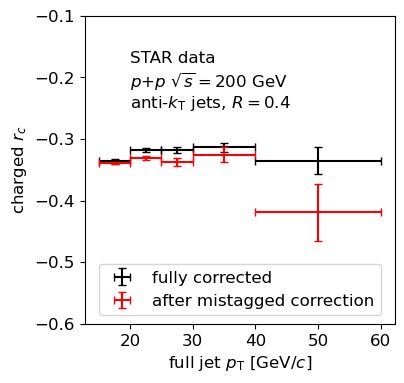

In [137]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_tot, capsize=3, color='k', ls='none', label='fully corrected')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='after mistagged correction')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR data\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# Check $r_c$ correction is not needed

In [39]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

In [40]:
rc_match_b_vs_pt_array = []
rc_err_match_b_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[0])
    rc_err_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[1])

Text(20, -0.25, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

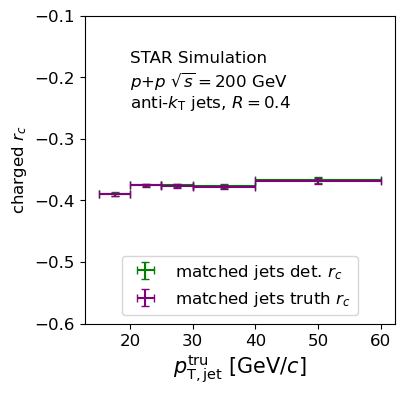

In [43]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='g', ls='none', label='matched jets det. $r_c$')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_b_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_b_vs_pt_array, capsize=3, color='purple', ls='none', label='matched jets truth $r_c$')
plt.xlabel('$p_{\mathrm{T,jet}}^{\mathrm{tru}}}$ [GeV$/c$]', fontsize=15)
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')